## Team Info

**Project Title:** Stars vs Sales: Do Product Reviews Actually Drive Success?  
**Team Name:** Data Detectives  

**Team Members and PIDs:**  
- Sonal Chakraborty — sonalchak  
- Vishana Baskaran — vishanab  
- Hari Balaji — balajihp27  

Roles:
Sonal - Project Intro, Question 3
Vishana - Question 2, 4
Hari - Question 1

## Project Intro

### Initial Description of the Project Topic

Product reviews are a major factor in how people decide what to buy online, but it is not always clear whether they truly reflect product quality. Sometimes products receive a large number of 5-star reviews simply because they are popular, not necessarily because they are better.

In this project, we will examine how star ratings and written reviews correspond to how well a product actually performs. By analyzing both the numerical ratings and the sentiment within review text, we aim to determine whether highly rated products are genuinely better or simply receive more engagement.

### Potential Research Questions
1. Do higher-rated products actually have higher sales or popularity?
2. Is the number of reviews more important than the average rating?
3. What words or patterns appear most frequently in positive vs negative reviews?
4. Are extreme reviews (1-star or 5-star) more influential than moderate reviews?

### Description of Potential Source Data
- Amazon product review datasets (from Kaggle)
  - includes star ratings, review text, number of reviews
  - also has product info like category, price, etc.
- Product popularity / sales data
  - Amazon sales rank (if available)
  - can help compare ratings vs actual success

In [1]:
import kagglehub
import pandas as pd
import matplotlib
import os
import numpy as np
import matplotlib.pyplot as plt

# Download latest version
path = kagglehub.dataset_download("ikramshah512/amazon-products-sales-dataset-42k-items-2025")
path = os.path.join(path, os.listdir(path)[0])

print("Path to dataset files:", path)

Path to dataset files: /Users/vishana/.cache/kagglehub/datasets/ikramshah512/amazon-products-sales-dataset-42k-items-2025/versions/1/amazon_products_sales_data_cleaned.csv


In [2]:
df = pd.read_csv(path)

In [3]:
df.to_csv('data.csv', index=False)


In [4]:
df.columns 

Index(['product_title', 'product_rating', 'total_reviews',
       'purchased_last_month', 'discounted_price', 'original_price',
       'is_best_seller', 'is_sponsored', 'has_coupon', 'buy_box_availability',
       'delivery_date', 'sustainability_tags', 'product_image_url',
       'product_page_url', 'data_collected_at', 'product_category',
       'discount_percentage'],
      dtype='object')

In [5]:
df.shape

(42675, 17)

In [6]:
#Isolate the relevent columns
df = df[['product_title', 'product_rating', 'total_reviews', 'purchased_last_month','is_best_seller']]

In [7]:
df.product_rating.value_counts()
# It seems 4.6 stars is the most common product rating, while 2.3-2.6 are the least common

product_rating
4.6    6151
4.4    5525
4.5    5359
4.7    4664
4.8    4230
4.3    2927
4.2    2837
4.1    1959
4.0    1465
3.9    1316
3.8    1083
5.0     995
4.9     704
3.6     666
3.7     604
3.2     363
3.5     242
3.4     216
3.0     148
2.0     143
2.7      15
1.5      15
3.3       6
2.8       4
1.0       4
2.4       3
2.9       2
3.1       2
2.3       1
2.5       1
2.6       1
Name: count, dtype: int64

### 1. First Research  Question: Do higher-rated products actually have higher sales or popularity?

This question investigates whether higher-rated Amazon products are actually more popular or have greater sales. Here, “higher-rated” refers to a product’s average star rating, while “popularity” is approximated by the total number of reviews. The hypothesis is that higher ratings are associated with greater popularity, as positive reviews may increase consumer trust and purchasing likelihood. 

Framed as a data science problem, this becomes an analysis of the relationship between rating and review count using methods such as correlation, regression, or visualization. This relationship depends on key assumptions and potential biases, however. Review count may reflect product age or visibility rather than true sales, ratings may be skewed by fake or extreme reviews, and popular products may receive more varied feedback, affecting their averages. Exploring this relationship helps determine whether ratings meaningfully signal product success, providing a foundation for further quantitative analysis.

We can answer this by seeing the correlation between product_rating and total_reviews/purchased_last_month

<Axes: >

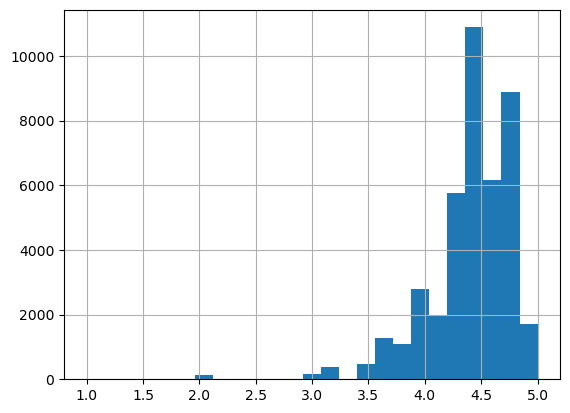

In [8]:
df.product_rating.hist(bins=25)
# Immedietely, we can see that the higher the rating, the more data is available for that rating

In [9]:
grouped_ratings = df.groupby("product_rating")[["total_reviews", "purchased_last_month"]].sum().reset_index()
grouped_ratings

,product_rating,total_reviews,purchased_last_month
0,1.0,4.0,0.0
1,1.5,75.0,0.0
2,2.0,288.0,7100.0
3,2.3,9.0,50.0
4,2.4,40.0,200.0
5,2.5,6.0,50.0
6,2.6,13.0,0.0
7,2.7,217.0,0.0
8,2.8,38.0,200.0
9,2.9,30.0,100.0


In [10]:
grouped_ratings.corr(numeric_only=True)
# Here, we can see that there is a positive correlation between product rating and the reviews/purchases

,product_rating,total_reviews,purchased_last_month
product_rating,1.000000,0.554302,0.338644
total_reviews,0.554302,1.000000,0.701897
purchased_last_month,0.338644,0.701897,1.000000


In [11]:
from sklearn.linear_model import LinearRegression
X = grouped_ratings[["product_rating"]]
y = grouped_ratings.total_reviews

lm = LinearRegression().fit(X, y)

grouped_ratings["predicted_total"] = lm.coef_ * X.product_rating + lm.intercept_

<Axes: xlabel='product_rating', ylabel='total_reviews'>

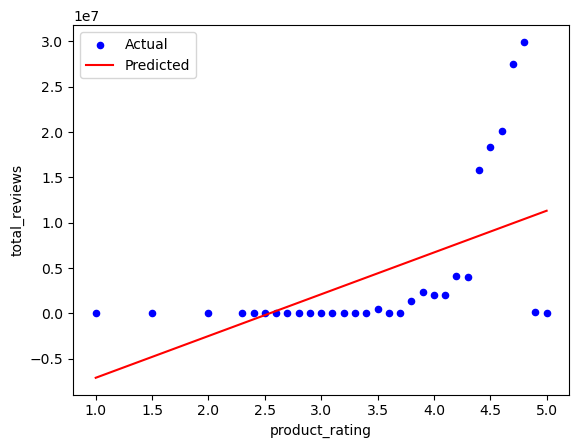

In [12]:
plot1 = grouped_ratings.plot.scatter(x="product_rating", y="total_reviews", color="blue", label="Actual")
grouped_ratings.plot(x="product_rating", y="predicted_total", color="red", label="Predicted", ax=plot1)

Clearly, there is a correlation, but it not quite linear. It looks a lot more exponential, so lets try to visualize that.

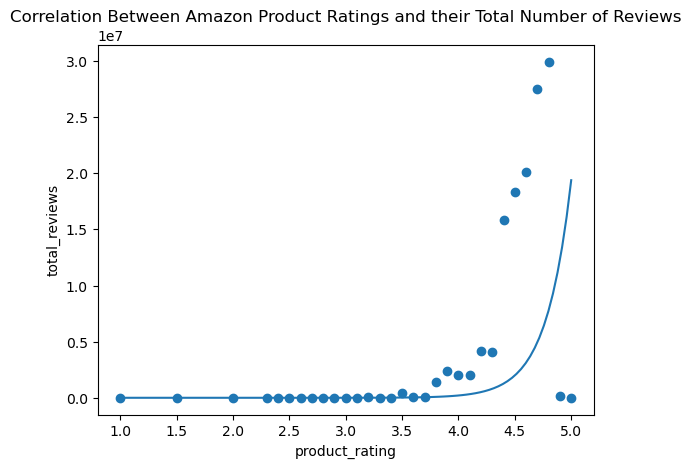

In [13]:
X = grouped_ratings["product_rating"]
log_y = np.log(y)

b, log_a = np.polyfit(X, log_y, 1)

a = np.exp(log_a)

X_fit = np.linspace(X.min(), X.max(), 100)
y_fit = a * np.exp(b * X_fit)

# Plot
plt.scatter(X, y)
plt.plot(X_fit, y_fit)
plt.xlabel("product_rating")
plt.ylabel("total_reviews")
plt.title("Correlation Between Amazon Product Ratings and their Total Number of Reviews")
plt.show()

From this analysis, we can see that the correlation sharply increases for rating higher than 4 stars. The exception is near 5 stars. It seems that a product getting a full 5 stars is quite rare. 

We can also check this for total sales

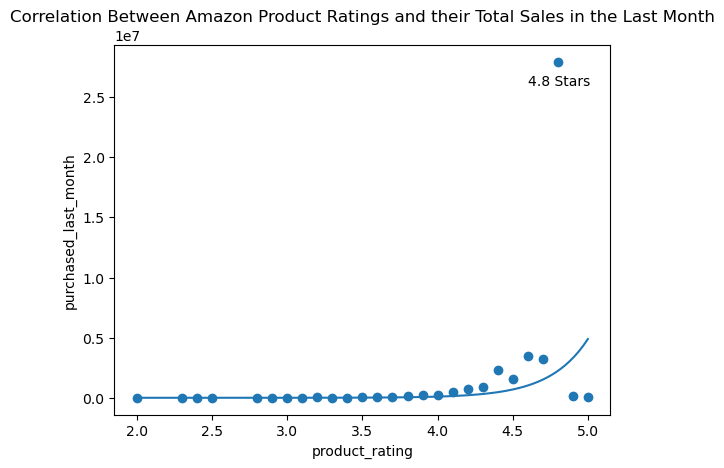

In [14]:
grouped_ratings_no_zeros = grouped_ratings[grouped_ratings.purchased_last_month > 0]
X = grouped_ratings_no_zeros["product_rating"]
y = grouped_ratings_no_zeros["purchased_last_month"]
log_y = np.log(y)

b, log_a = np.polyfit(X, log_y, 1)

a = np.exp(log_a)

X_fit = np.linspace(X.min(), X.max(), 100)
y_fit = a * np.exp(b * X_fit)

# Plot
plt.scatter(X, y)
plt.plot(X_fit, y_fit)
plt.xlabel("product_rating")
plt.ylabel("purchased_last_month")
plt.title("Correlation Between Amazon Product Ratings and their Total Sales in the Last Month")
plt.annotate('4.8 Stars', xy=(4.8, 27942900), xytext=(4.6, 25942900))
plt.show()

It seems there is a massive outlier at 4.8 stars when it comes to produch sales. Products rated at 4.8 are **by far** the most popular. Like the rating vs total reviews graph, the y values start to increase significantly starting at 4 stars, with a sudden drop near 5 stars.

### Question 1 Conclusion

The analysis suggests that higher-rated products do tend to be more popular, but only beyond a certain threshold. Popularity increases noticeably once ratings exceed about 4 stars, with a peak around 4.8, after which both review counts and estimated sales drop off near a perfect 5. This indicates that while strong ratings are associated with success, a flawless rating is uncommon and may not signal maximum popularity. One possible interpretation is that highly popular products receive more diverse feedback, preventing perfect scores, while slightly lower—but still excellent—ratings like 4.8 reflect both high sales and broad customer engagement.

However, review count is only a proxy for sales and may be influenced by product age, visibility, or platform dynamics, while ratings themselves may be biased by fake reviews or selective feedback. The observed peak at 4.8 could also be driven by outliers rather than a general trend. Overall, the results refine the original question: rather than asking whether higher ratings always lead to greater popularity, it appears that moderately high (but not perfect) ratings are most indicative of success.



### 2. Second Research Question: Is the number of reviews more important than the average rating?
This question looks at whether people are influenced more by how many reviews a product has or how high its rating is when deciding to buy it. Here, purchasing behavior is represented by purchased_last_month, while the two factors we compare are product_rating and total_reviews.

From a data science perspective, this becomes a comparison of how strongly each variable relates to recent sales. We examine this using correlation, multiple linear regression with standardized features, and visualizations. Standardizing the variables allows us to directly compare the regression coefficients to see which feature has greater influence on purchases.

There are also important assumptions and limitations to consider. A product with many reviews may simply be older, more visible, or more widely promoted. Ratings can be skewed by extreme opinions, fake reviews, or small sample sizes. Because of this, a high rating does not always guarantee high sales, and a large number of reviews may reflect popularity rather than quality.

In [15]:
#Check correlations between those variables
corrs = df[['product_rating', 'total_reviews', 'purchased_last_month']].corr()
print("Correlation with Sales:")
print(corrs['purchased_last_month'].sort_values(ascending=False))

Correlation with Sales:
purchased_last_month    1.000000
total_reviews           0.295952
product_rating          0.151883
Name: purchased_last_month, dtype: float64


Correlation between product rating and sales is half of that for total reviews and sales --> suggests that review number may be more important

In [16]:
from sklearn.preprocessing import StandardScaler

#clean data
df = df.dropna().copy()
df = df[df['purchased_last_month'] > 0]

# standardize data
scaler = StandardScaler()
X_multi = df[['product_rating', 'total_reviews']]
X_scaled = scaler.fit_transform(X_multi)
y = df['purchased_last_month']

# multiple linear regression - see how total reviews and product rating impact sales
multi_model = LinearRegression().fit(X_scaled, y)
print("Coefficients (Importance)")
print(f"Rating Importance: {multi_model.coef_[0]}")
print(f"Review Volume Importance: {multi_model.coef_[1]}")

Coefficients (Importance)
Rating Importance: 780.1918781324016
Review Volume Importance: 1793.4828590404336


When analyzing the coefficients for the multiple regression model, we can see that both of the factors have an important impact (as they are both positive), but, the review volume has a much higher importance than the product rating, which is consistent with the correlation analysis we did earlier. This suggests that while star rating does have an impact on sales, the number of reviews is a much stronger predictor of sales performance.

In [17]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

# 1. Clean data (Ensure sales > 0 because log(0) is undefined)
df_exp = df[['product_rating', 'total_reviews', 'purchased_last_month']].dropna().copy()
df_exp = df_exp[df_exp['purchased_last_month'] > 0]

# 2. Standardize predictors (X)
scaler = StandardScaler()
X_multi = df_exp[['product_rating', 'total_reviews']]
X_scaled = scaler.fit_transform(X_multi)

# 3. Transform the target (y) to Log scale for an exponential relationship
# This is the key step that makes it an "exponential" model
y_log = np.log(df_exp['purchased_last_month'])

# 4. Fit the model on the logged data
multi_model = LinearRegression().fit(X_scaled, y_log)

print("Exponential Model Results (Log-Scale)")
print(f"Rating Coefficient: {multi_model.coef_[0]:.4f}")
print(f"Review Volume Coefficient: {multi_model.coef_[1]:.4f}")

Exponential Model Results (Log-Scale)
Rating Coefficient: 0.3428
Review Volume Coefficient: 0.3550


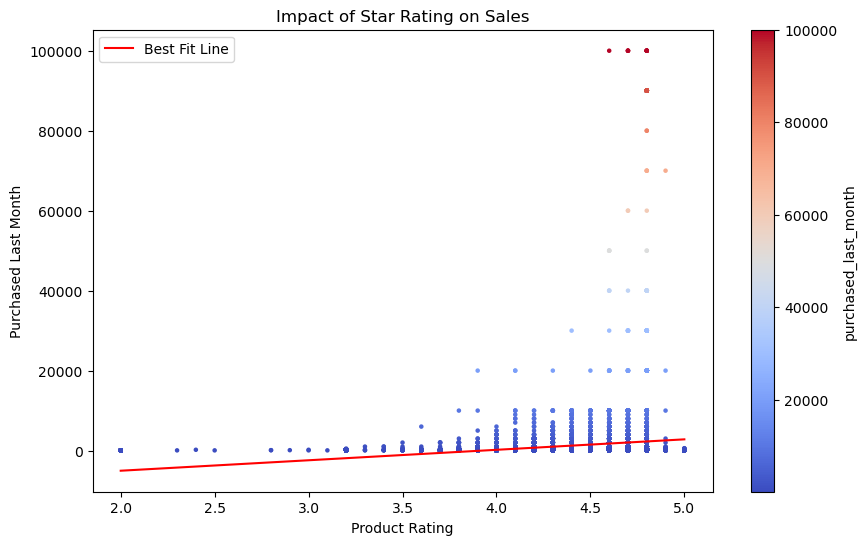

In [18]:
#ratings visualization
model1 = LinearRegression().fit(df[['product_rating']], y)

plot1 = df.plot.scatter(x="product_rating", y="purchased_last_month", 
                            c="purchased_last_month", figsize=(10, 6), 
                            colormap="coolwarm", s=5, colorbar=True)

plot1.set_xlabel("Product Rating")
plot1.set_ylabel("Purchased Last Month")
plot1.set_title("Impact of Star Rating on Sales")

# regression line for rating
xs_1 = np.array([df["product_rating"].min(), df["product_rating"].max()])
ys_1 = model1.coef_[0] * xs_1 + model1.intercept_
plot1.plot(xs_1, ys_1, color='red', label='Best Fit Line')
plot1.legend()

Looking at the plot of ratings vs sales (and the regression line), we can see that there is a positive relationship between the two, but it is not very strong, as there is a lot of variability in sales for each rating level. This suggests that while star rating does have an impact on sales, it is not the only factor at play. Sometimes, products with extremely high ratings get less sales than those with lower ratings.

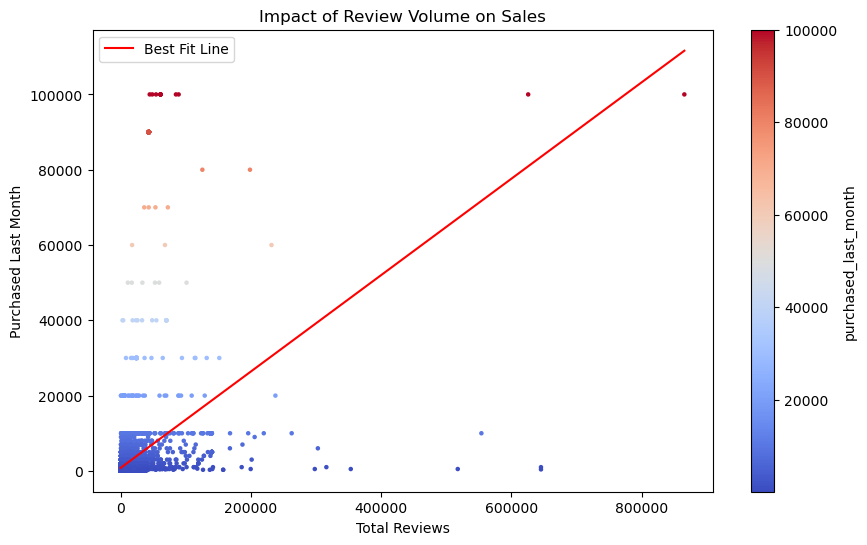

In [19]:
# reviews visualization


model2 = LinearRegression().fit(df[['total_reviews']], y)

plot2 = df.plot.scatter(x="total_reviews", y="purchased_last_month", 
                            c="purchased_last_month", figsize=(10, 6), 
                            colormap="coolwarm", s=5, colorbar=True)

plot2.set_xlabel("Total Reviews")
plot2.set_ylabel("Purchased Last Month")
plot2.set_title("Impact of Review Volume on Sales")

# regression line for reviews
xs_2 = np.array([df["total_reviews"].min(), df["total_reviews"].max()])
ys_2 = model2.coef_[0] * xs_2 + model2.intercept_
plot2.plot(xs_2, ys_2, color='red', label='Best Fit Line')
plot2.legend()

The review volume graph shows a much steeper and more consistent upward trend than the star rating graph, showing that sales scale more directly with the quantity of feedback than with the star score itself. This directly aligns with the correlation and regression analyses we did earlier.

## Conclusion
The analysis shows that both star rating and review count are positively related to recent purchases, but review volume is the stronger predictor. Correlation results, standardized regression coefficients, and visualizations all indicate that sales increase more consistently with the number of reviews than with the rating itself. While higher ratings do relate to higher purchases, the relationship is weaker and shows much more variability.

This suggests that consumers may be influenced more by social proof (how many people reviewed a product) than by the exact star score. However, review count can be affected by factors such as product age, visibility, or marketing exposure, and ratings may be skewed by biased or extreme feedback. Overall, the findings refine the question: rather than rating being the main driver of purchases, the quantity of feedback appears to play a larger role in signaling product success.

### Question 3. Are extreme reviews (1-star or 5-star) more influential than moderate reviews?
We can answer this by grouping products into rating categories (low, moderate, and high) and comparing how each group performs in terms of sales and total reviews.

In [20]:
#Create Categories
def categorize_rating(r):
    if r <= 2:
        return "Low (1-2)"
    elif r >= 4.5:
        return "High (4.5-5)"
    else:
        return "Moderate (2-4.5)"

df["rating_category"] = df["product_rating"].apply(categorize_rating)

In [21]:
#Compare averages
category_stats = df.groupby("rating_category")[["purchased_last_month", "total_reviews"]].mean()
print(category_stats)

                  purchased_last_month  total_reviews
rating_category                                      
High (4.5-5)               2022.589325    4989.905293
Low (1-2)                    50.000000       2.000000
Moderate (2-4.5)            369.390174    2253.251760


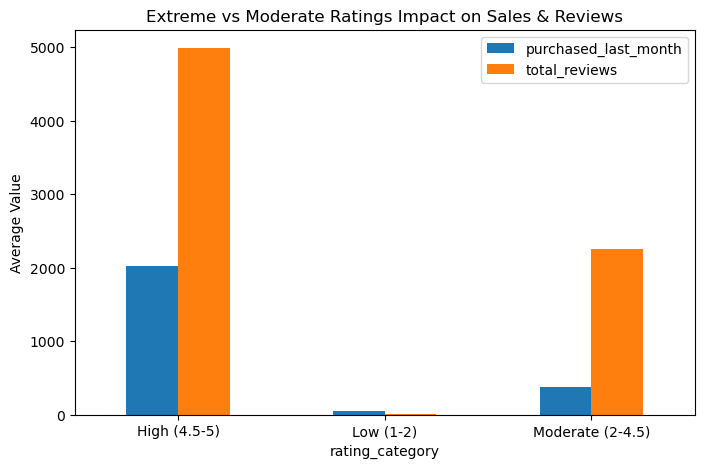

In [22]:
#Visualize it
category_stats.plot(kind="bar", figsize=(8,5))
plt.title("Extreme vs Moderate Ratings Impact on Sales & Reviews")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.show()

Products with ratings close to 5 stars clearly do way better in sales and engagement. The moderate rated ones are pretty average and the low rated ones barely get any attention. Overall, this shows that really high ratings matter a lot more than moderate ones when it comes to driving product success. 

## Question 4: Does the language of a review reflect its star rating and are they similarly helpful?

This question looks at whether the words people use in Amazon reviews match the star ratings they give, and whether those words can help explain how well a product sells. Here, “sentiment” means how positive or negative a review sounds, and product success is measured by purchased_last_month. The basic idea is that higher star ratings should usually come with more positive language, but written reviews might show opinions that ratings alone don’t fully capture.

From a data science perspective, this becomes a comparison of star rating, review sentiment, and purchases. We use tools like correlation and regression to see how these variables relate to each other. This analysis assumes that sentiment scoring correctly captures meaning from text, but in reality reviews can include sarcasm, mixed feelings, or unclear wording. Ratings also don’t always perfectly match what people write, which can create differences between the two signals.

We can answer this by checking how strongly sentiment relates to product_rating, and by comparing whether sentiment, product_rating, or total_reviews is the best predictor of purchased_last_month.

In [117]:
# Open a new dataset (this one specifically has the text of the reviews)
# Initially tried to merge with existiing dataset, but there was no overlap and fuzzy matching with the product titles wasn't effective
path2 = kagglehub.dataset_download("karkavelrajaj/amazon-sales-dataset")
path2 = os.path.join(path2, os.listdir(path2)[0])

print("Path to dataset files:", path2)

df_rev = pd.read_csv(path2)


Path to dataset files: /Users/vishana/.cache/kagglehub/datasets/karkavelrajaj/amazon-sales-dataset/versions/1/amazon.csv


In [122]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import os
import re
from collections import Counter

# Download the amazon sales/reviews dataset
path_reviews = kagglehub.dataset_download("karkavelrajaj/amazon-sales-dataset")
rev_file = os.path.join(path_reviews, os.listdir(path_reviews)[0])
df_rev = pd.read_csv(rev_file)

print("Shape:", df_rev.shape)
print("Columns:", df_rev.columns.tolist())
df_rev.head(3)

Shape: (1465, 16)
Columns: ['product_id', 'product_name', 'category', 'discounted_price', 'actual_price', 'discount_percentage', 'rating', 'rating_count', 'about_product', 'user_id', 'user_name', 'review_id', 'review_title', 'review_content', 'img_link', 'product_link']


,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...


In [123]:
import nltk
nltk.download('opinion_lexicon', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
from nltk.corpus import opinion_lexicon

pos_words = set(opinion_lexicon.positive())
neg_words = set(opinion_lexicon.negative())

def compute_sentiment(text):
    if pd.isna(text) or not isinstance(text, str) or not text.strip():
        return np.nan
    tokens = re.findall(r'[a-z]+', text.lower())
    if not tokens:
        return np.nan
    pos = sum(1 for w in tokens if w in pos_words)
    neg = sum(1 for w in tokens if w in neg_words)
    return (pos - neg) / len(tokens)

def review_length(text):
    if pd.isna(text) or not isinstance(text, str):
        return np.nan
    return len(re.findall(r'[a-z]+', text.lower()))

# Clean and compute
df_rev['review_content'] = df_rev['review_content'].astype(str)
df_rev['Sentiment'] = df_rev['review_content'].apply(compute_sentiment)
df_rev['review_length'] = df_rev['review_content'].apply(review_length)

# Clean star rating to numeric
df_rev['rating'] = pd.to_numeric(df_rev['rating'], errors='coerce')

print(f"Reviews with sentiment scores: {df_rev['Sentiment'].notna().sum()}")
print("\nSample rows:")
df_rev[['rating', 'review_content', 'Sentiment', 'review_length']].dropna().head(4)

Reviews with sentiment scores: 1465

Sample rows:


,rating,review_content,Sentiment,review_length
0,4.2,Looks durable Charging is fine tooNo complains...,0.109756,82
1,4.0,I ordered this cable to connect my phone to An...,0.059361,219
2,3.9,"Not quite durable and sturdy,https://m.media-a...",0.122449,49
3,4.2,"Good product,long wire,Charges good,Nice,I bou...",0.129412,85


/var/folders/sp/csnyn_xd6nn74nw2y7vbjm9w0000gn/T/ipykernel_6331/768767737.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


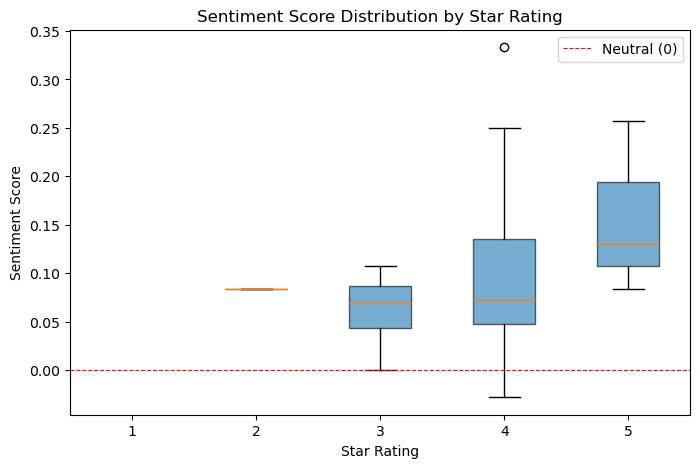

Pearson correlation between rating and sentiment: 0.128


In [129]:

df_plot = df_rev.dropna(subset=['Sentiment', 'rating'])

groups = [df_plot[df_plot['rating'] == r]['Sentiment'].dropna() for r in [1, 2, 3, 4, 5]]

fig, ax = plt.subplots(figsize=(8, 5))

ax.boxplot(
    groups,
    labels=['1', '2', '3', '4', '5'],
    patch_artist=True,
    boxprops=dict(alpha=0.6)
)

ax.axhline(0, color='red', linestyle='--', linewidth=0.8, label='Neutral (0)')
ax.set_xlabel('Star Rating')
ax.set_ylabel('Sentiment Score')
ax.set_title('Sentiment Score Distribution by Star Rating')
ax.legend()

plt.savefig('sentiment_by_rating.png', dpi=150, bbox_inches='tight')
plt.show()

corr = df_plot[['rating', 'Sentiment']].corr().iloc[0, 1]
print(f"Pearson correlation between rating and sentiment: {corr:.3f}")

There's a positive correlation between rating and sentiment, which is positive but not that high. It looks like it's more closely tied when the rating is higher.


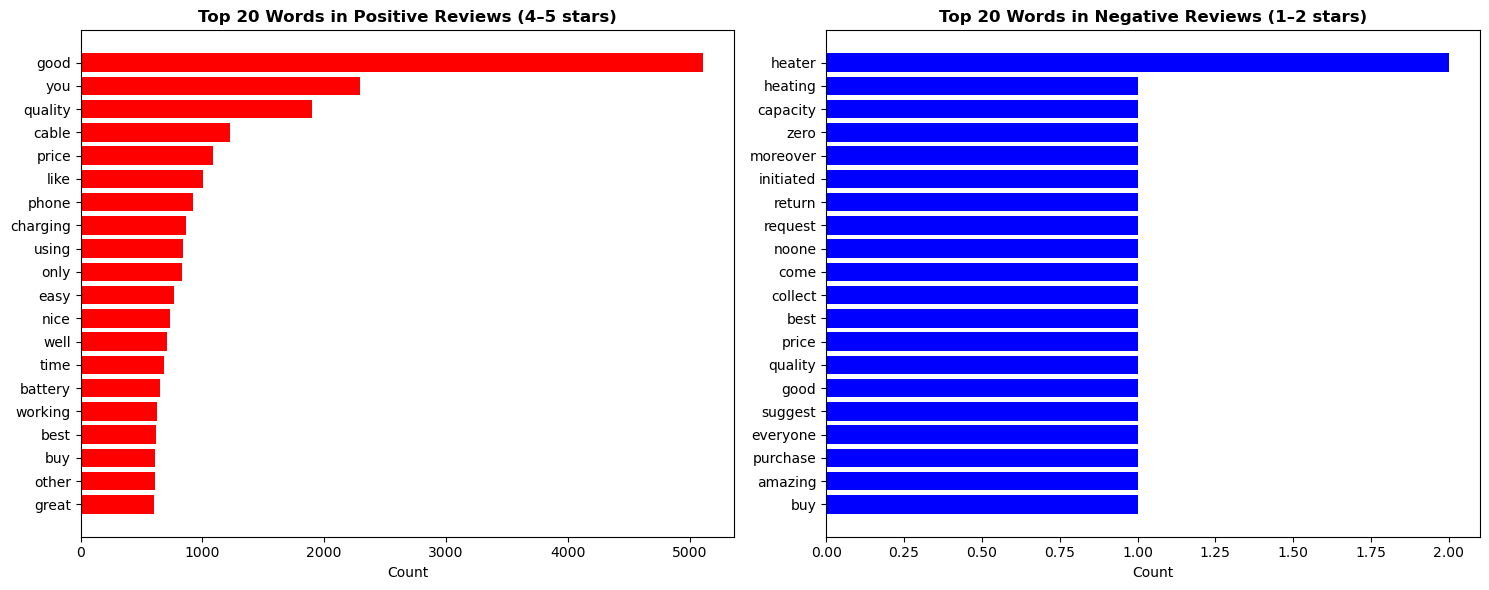

In [133]:
# get rid of common words
common_words = {'the','a','an','and','or','but','in','on','at','to','for','of',
             'with','it','is','was','i','my','this','that','have','not','be',
             'its','very','so','are','as','do','we','has','had','they','me',
             'get','got','just','if','from','use','used','been','would','will',
             'can','all','one','more','also','than','up','out','no','about',
             'after','when','what','which','your','their','there','product',
             'review','amazon','item','order','received','delivery','shipping'}

def top_words(texts, n=20):
    tokens = []
    for t in texts:
        if pd.notna(t):
            tokens.extend(w for w in re.findall(r'[a-z]+', str(t).lower())
                          if w not in common_words and len(w) > 2)
    return Counter(tokens).most_common(n)

pos_reviews = df_rev[df_rev['rating'] >= 4]['review_content']
neg_reviews = df_rev[df_rev['rating'] <= 2]['review_content']

top_pos = top_words(pos_reviews)
top_neg = top_words(neg_reviews)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

words_p, counts_p = zip(*top_pos)
axes[0].barh(words_p[::-1], counts_p[::-1], color='red')
axes[0].set_title('Top 20 Words in Positive Reviews (4–5 stars)', fontweight='bold')
axes[0].set_xlabel('Count')

words_n, counts_n = zip(*top_neg)
axes[1].barh(words_n[::-1], counts_n[::-1], color='blue')
axes[1].set_title('Top 20 Words in Negative Reviews (1–2 stars)', fontweight='bold')
axes[1].set_xlabel('Count')

plt.tight_layout()
plt.savefig('top_words.png', dpi=150, bbox_inches='tight')
plt.show()

Honestly it seems like a lot of the common words relate to the product itself, but there are just as many positive words like good, amazing and best in the negative reviews as well. This most likely explains why correlation is not high between sentiment and ratings, maybe because of double negatives